# PCA y Sobol con condiciones iniciales y de frontera duras

Transformación: $u_\theta(x,t)=-\sin(\pi x)+t(1-x^2)N_\theta(x,t)$. Impone IC y BC homogéneas; una corrección del seno en x=±1 elimina redondeo float32. El residuo y sus derivadas automáticas se calculan sobre toda la solución transformada. La pérdida hard es **datos supervisados + PDE**: se conserva la información supervisada; IC y BC dejan de ser penalizaciones.

La referencia soft usa datos+PDE+10 IC, sin BC explícita, del notebook 24. Cambiar imposición modifica también el espacio de soluciones y la optimización: no es solo cambiar un coeficiente de pérdida. La transformación se aplica desde la inicialización, incluido el warmup; la referencia aplica IC10 después de su warmup original. Por tanto, los brazos hard y soft comparten semilla y parámetros crudos iniciales, pero sus estados tras cien pasos son distintos. Dentro de hard, PCA y Sobol comparten exactamente el warmup.

Diez semillas 2071–2080, 100 pasos uniformes y 10000 de continuación, red 3×32 y Adam constante, mismos datos supervisados y particiones. PCA usa reconstrucción, candidatos fijos, media + componentes al 95 %, QR directo, veinte snapshots cada cinco pasos del último intervalo de cien. Se completa a 128 con Sobol; el control usa 128 Sobol. No se utiliza poda. Las referencias soft se reutilizan; manifest.json identifica las rutas. Es una extensión exploratoria sobre las semillas de confirmación anteriores, no otra confirmación independiente.

| Condiciones | Selector | RMSE prueba ± DE | Residuo RMS | RMSE IC | RMS BC |
|---|---|---:|---:|---:|---:|
| soft_ic10 | pca | 0.06191 ± 0.01464 | 0.24614 | 2.30e-02 | 1.49e-02 |
| soft_ic10 | sobol | 0.05982 ± 0.04083 | 0.43213 | 1.97e-02 | 1.30e-02 |
| hard | pca | 0.09571 ± 0.03993 | 0.28964 | 6.60e-08 | 0.00e+00 |
| hard | sobol | 0.08287 ± 0.04815 | 0.59858 | 6.60e-08 | 0.00e+00 |


PCA minus Sobol (soft_ic10): diferencia media +0.00209; mejora en 4/10 semillas; intervalo bootstrap 95 % [-0.02733, +0.02672].

PCA minus Sobol (hard): diferencia media +0.01284; mejora en 2/10 semillas; intervalo bootstrap 95 % [-0.03147, +0.05014].

hard minus soft (pca): diferencia media +0.03380; mejora en 3/10 semillas; intervalo bootstrap 95 % [+0.00612, +0.06258].

hard minus soft (sobol): diferencia media +0.02305; mejora en 3/10 semillas; intervalo bootstrap 95 % [-0.01843, +0.06661].

**Comparación**

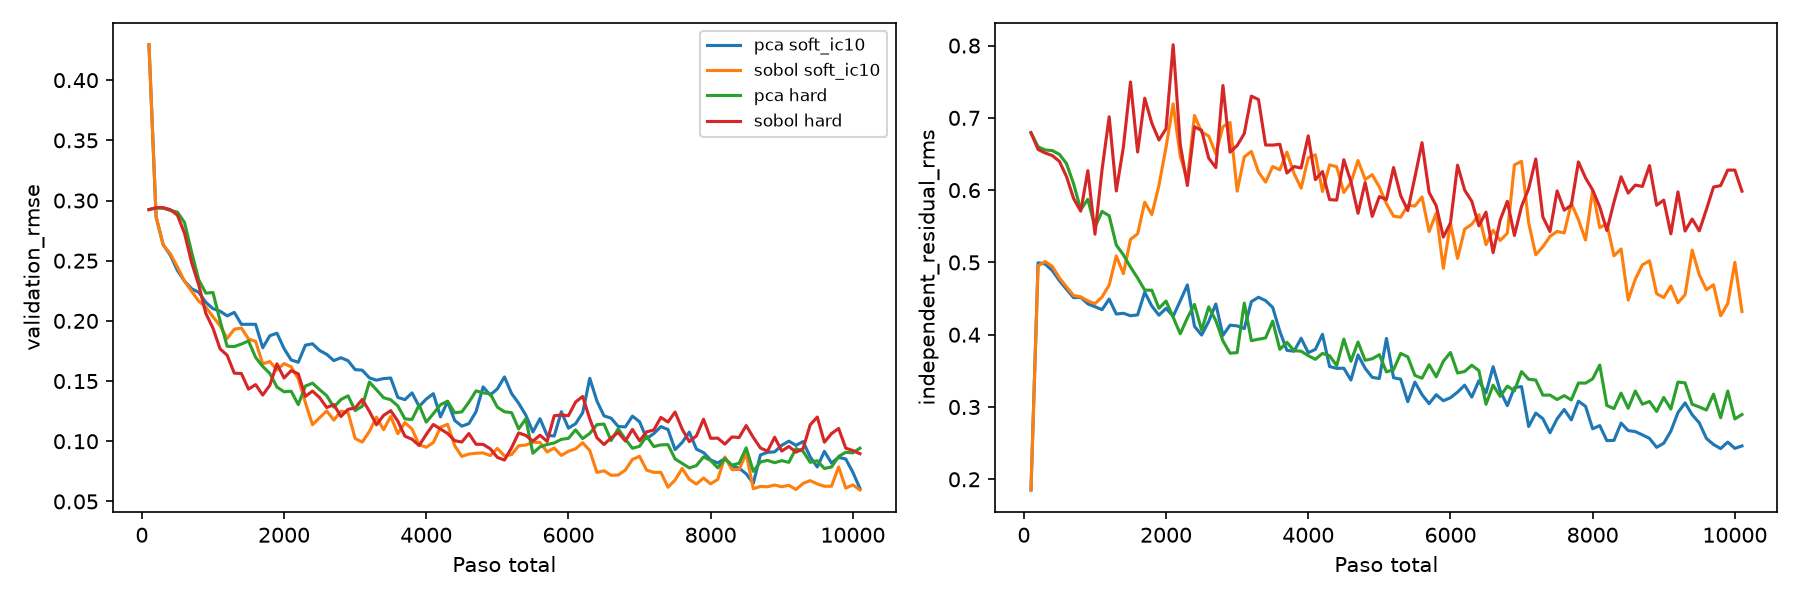

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/hard_conditions/hard_ic_bc_data_10seeds_10k_v1/comparison.png'), format='png', embed=True))


Las métricas terminales se evalúan en prueba reservada sin elegir por prueba. El bootstrap pareado con diez semillas tiene incertidumbre y no corrige multiplicidad. DE es dispersión entre semillas. IC global se compara con el archivo de referencia y puede tener redondeo distinto de la identidad analítica. constraints.csv verifica máximos analíticos IC y BC en una malla independiente, incluidos extremos y t=1. history_audit.npz conserva historias del residuo transformado con sus coordenadas. No se afirma aceleración: la transformación agrega derivadas y PCA requiere observar candidatos.

Reproducir: `python scripts/run_collocation_hard_conditions.py`. Las corridas completas se reutilizan. El objetivo conserva datos supervisados; retirarlos para una comparación puramente física sería otro control. Las figuras están incrustadas como PNG.